# Hydroelectric Reservoir Scheduling: Rockafellian + CVaR-CC
## Framework completo paso a paso

**Problema:** Dos embalses en cascada, 12 meses, inflows estocasticos.
Maximizar revenue electrico sujeto a que los volumenes se mantengan
dentro de limites con probabilidad >= 90%.

**5 Escenarios:**
1. **Base** (sigma=0.4): Caso principal
2. **Poco volatil** (sigma=0.25): Inflows predecibles
3. **Muy volatil** (sigma=0.6): Alta incertidumbre
4. **Sequia** (mu reducido 25%): Inflows bajos
5. **Embalses chicos** (V_max reducido 30%): Menos buffer


In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

N_OPT = 1000
N_MC = 2000
ALPHA = 0.10
GAMMA_PATH = [10**k for k in [2.0, 2.6, 3.2, 3.8, 4.4, 5.0]]

C_CVAR = '#2196F3'
C_CC = '#F44336'
C_MC = '#4CAF50'
C_TGT = '#000000'

print("Configuracion:")
print(f"  N_OPT = {N_OPT}, N_MC = {N_MC}, alpha = {ALPHA}")


Configuracion:
  N_OPT = 1000, N_MC = 2000, alpha = 0.1


## 1. El Problema

### Reservoir Scheduling con Chance Constraint

Dos embalses en cascada. El embalse 1 (arriba) descarga al embalse 2 (abajo).
En cada mes $t$, el operador decide cuanto turbinar $x_{t,r} \in [0, x_{\max,r}]$.

**Dinamica:**
$$V_{t+1,r} = V_{t,r} + I_{t,r}(\xi) - x_{t,r} + x_{t,r-1} \cdot \mathbf{1}(r>1)$$

**Restriccion:** Volumenes dentro de limites en TODOS los meses y AMBOS embalses,
con probabilidad >= 90%.

**Funcion de perdida:**
$$L(x,\xi) = \max_{t,r} \max\left(V_{\min,r} - V_{t,r},\; V_{t,r} - V_{\max,r}\right)$$

**Objetivo:** Maximizar revenue $\sum_{t,r} p_t \cdot x_{t,r}$ (precios estacionales).


In [24]:
T = 12
N_RES = 2
V_MAX_BASE = np.array([500., 300.])
V_MIN_BASE = np.array([100., 50.])
V_0 = np.array([300., 200.])
X_MAX = np.array([100., 150.])
MU_I_BASE = np.array([40., 30.])
SIGMA_I_BASE = 0.4
PRICES = np.array([50 + 20*np.sin(np.pi*t/T) for t in range(T)])

print("PARAMETROS DEL RESERVORIO")
print("=" * 60)
print(f"  Periodos T = {T} meses")
print(f"  Embalse 1: V in [{V_MIN_BASE[0]}, {V_MAX_BASE[0]}] Mm3, V0={V_0[0]}, x_max={X_MAX[0]}")
print(f"  Embalse 2: V in [{V_MIN_BASE[1]}, {V_MAX_BASE[1]}] Mm3, V0={V_0[1]}, x_max={X_MAX[1]}")
print(f"  Inflows: LogNormal(mu={MU_I_BASE}, sigma={SIGMA_I_BASE})")
print(f"  Precios: {PRICES.round(1)}")
print()

scenarios = [
    {'name': '1. Base',          'mu_I': MU_I_BASE.copy(), 'sigma_I': 0.4,
     'V_max': V_MAX_BASE.copy(), 'V_min': V_MIN_BASE.copy(), 'desc': 'sigma=0.4'},
    {'name': '2. Poco volatil',  'mu_I': MU_I_BASE.copy(), 'sigma_I': 0.25,
     'V_max': V_MAX_BASE.copy(), 'V_min': V_MIN_BASE.copy(), 'desc': 'sigma=0.25'},
    {'name': '3. Muy volatil',   'mu_I': MU_I_BASE.copy(), 'sigma_I': 0.6,
     'V_max': V_MAX_BASE.copy(), 'V_min': V_MIN_BASE.copy(), 'desc': 'sigma=0.6'},
    {'name': '4. Sequia',        'mu_I': MU_I_BASE*0.75, 'sigma_I': 0.4,
     'V_max': V_MAX_BASE.copy(), 'V_min': V_MIN_BASE.copy(), 'desc': 'mu*0.75'},
    {'name': '5. Emb. chicos',   'mu_I': MU_I_BASE.copy(), 'sigma_I': 0.4,
     'V_max': V_MAX_BASE*0.7, 'V_min': V_MIN_BASE.copy(), 'desc': 'V_max*0.7'},
]

print("ESCENARIOS")
print("=" * 60)
for s in scenarios:
    print(f"  {s['name']}: {s['desc']}")


PARAMETROS DEL RESERVORIO
  Periodos T = 12 meses
  Embalse 1: V in [100.0, 500.0] Mm3, V0=300.0, x_max=100.0
  Embalse 2: V in [50.0, 300.0] Mm3, V0=200.0, x_max=150.0
  Inflows: LogNormal(mu=[40. 30.], sigma=0.4)
  Precios: [50.  55.2 60.  64.1 67.3 69.3 70.  69.3 67.3 64.1 60.  55.2]

ESCENARIOS
  1. Base: sigma=0.4
  2. Poco volatil: sigma=0.25
  3. Muy volatil: sigma=0.6
  4. Sequia: mu*0.75
  5. Emb. chicos: V_max*0.7


In [25]:
def generate_inflows(mu_I, sigma_I, N, seed=42):
    np.random.seed(seed)
    return np.random.lognormal(mean=np.log(mu_I), sigma=sigma_I, size=(N, T, N_RES))

inflow_opt = generate_inflows(MU_I_BASE, SIGMA_I_BASE, N_OPT, seed=42)
inflow_mc = generate_inflows(MU_I_BASE, SIGMA_I_BASE, N_MC, seed=123)

print("Escenarios generados (caso base):")
print(f"  Optimizacion: {inflow_opt.shape}, Validacion MC: {inflow_mc.shape}")
print(f"  Inflow medio R1: {inflow_opt[:,:,0].mean():.1f}, R2: {inflow_opt[:,:,1].mean():.1f}")


Escenarios generados (caso base):
  Optimizacion: (1000, 12, 2), Validacion MC: (2000, 12, 2)
  Inflow medio R1: 43.5, R2: 32.5


In [26]:
def simulate_reservoir(x_flat, inflow, V_0, V_min, V_max):
    N = inflow.shape[0]
    x = x_flat.reshape(T, N_RES)
    V = np.zeros((N, T, N_RES))
    for t in range(T):
        for r in range(N_RES):
            V_prev = V_0[r] if t == 0 else V[:, t-1, r]
            upstream = x[t, r-1] if r > 0 else 0.0
            V[:, t, r] = V_prev + inflow[:, t, r] - x[t, r] + upstream
    L = np.full(N, -np.inf)  # <-- ESTE ES EL CAMBIO
    for t in range(T):
        for r in range(N_RES):
            L = np.maximum(L, V_min[r] - V[:, t, r])
            L = np.maximum(L, V[:, t, r] - V_max[r])
    return V, L

def compute_revenue(x_flat):
    x = x_flat.reshape(T, N_RES)
    return sum(PRICES[t] * x[t, r] for t in range(T) for r in range(N_RES))

def compute_cvar(L, alpha):
    N = len(L)
    sorted_L = np.sort(L)
    idx = min(int(np.ceil((1 - alpha) * N)) - 1, N - 1)
    var = sorted_L[max(idx, 0)]
    cvar = var + (1.0 / alpha) * np.mean(np.maximum(L - var, 0.0))
    return cvar, var

def compute_bpoe(L, tol=0.001):
    a_lo, a_hi = 0.001, 0.999
    for _ in range(60):
        a_mid = (a_lo + a_hi) / 2
        c, _ = compute_cvar(L, a_mid)
        if c <= 0: a_hi = a_mid
        else: a_lo = a_mid
        if a_hi - a_lo < tol: break
    return (a_lo + a_hi) / 2

# Test
x_test = np.array([[mu for mu in MU_I_BASE] for _ in range(T)]).flatten()
V_test, L_test = simulate_reservoir(x_test, inflow_opt, V_0, V_MIN_BASE, V_MAX_BASE)
cvar_t, var_t = compute_cvar(L_test, ALPHA)
print("Test politica balanceada (x = inflow medio):")
print(f"  Revenue = ${compute_revenue(x_test):.0f}")
print(f"  P(L>0) = {np.mean(L_test > 0):.3f}")
print(f"  CVaR = {cvar_t:.2f}, VaR = {var_t:.2f}")


Test politica balanceada (x = inflow medio):
  Revenue = $52634
  P(L>0) = 1.000
  CVaR = 499.86, VaR = 469.27


## 2. Entender la fisica: trayectorias de volumen


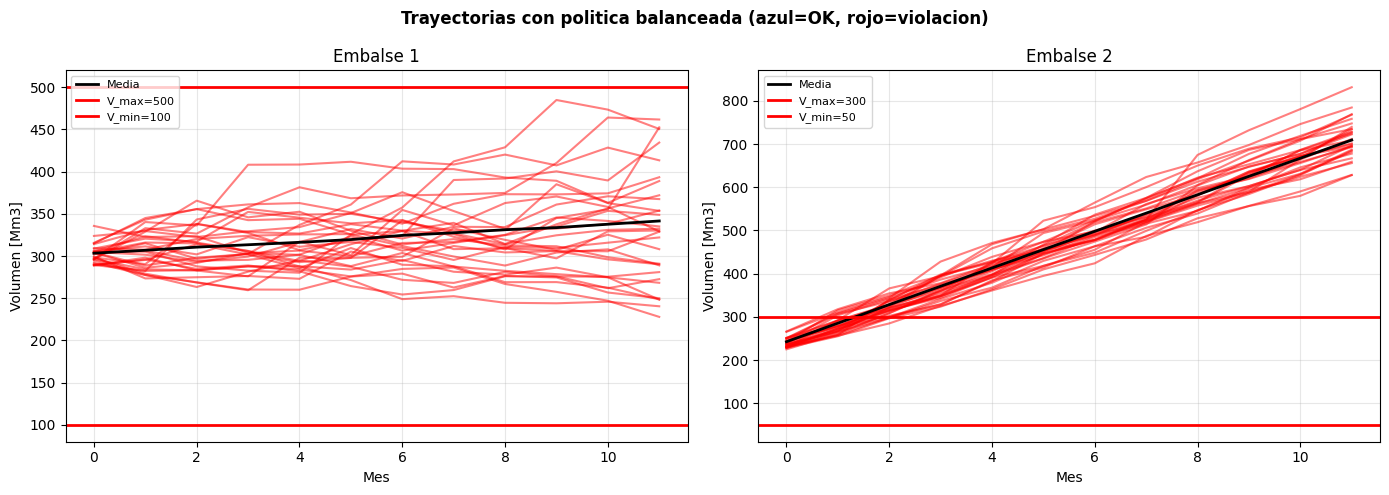

Reliability: 0.0%


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x_bal = np.array([[MU_I_BASE[r] for r in range(N_RES)] for _ in range(T)]).flatten()
V_bal, L_bal = simulate_reservoir(x_bal, inflow_opt, V_0, V_MIN_BASE, V_MAX_BASE)
for r in range(N_RES):
    ax = axes[r]
    for s in range(30):
        color = 'red' if L_bal[s] > 0 else 'steelblue'
        a = 0.5 if L_bal[s] > 0 else 0.15
        ax.plot(range(T), V_bal[s, :, r], color=color, alpha=a)
    ax.plot(range(T), V_bal[:,:,r].mean(axis=0), 'k-', lw=2, label='Media')
    ax.axhline(y=V_MAX_BASE[r], color='red', lw=2, label=f'V_max={V_MAX_BASE[r]:.0f}')
    ax.axhline(y=V_MIN_BASE[r], color='red', lw=2, label=f'V_min={V_MIN_BASE[r]:.0f}')
    ax.set_xlabel('Mes'); ax.set_ylabel('Volumen [Mm3]')
    ax.set_title(f'Embalse {r+1}'); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
plt.suptitle('Trayectorias con politica balanceada (azul=OK, rojo=violacion)', fontweight='bold')
plt.tight_layout(); plt.show()
print(f"Reliability: {100*np.mean(L_bal<=0):.1f}%")


In [28]:
print("POLITICAS EXTREMAS")
print("=" * 65)
print(f"{'Politica':>25} {'Rel':>8} {'Revenue':>10} {'L_max':>8}")
print("-" * 55)
for name, x_f in [
    ("Minimo (x=0)", np.zeros(T*N_RES)),
    ("Bajo (0.5*mu)", np.array([[MU_I_BASE[r]*0.5 for r in range(N_RES)] for _ in range(T)]).flatten()),
    ("Balanceado (mu)", x_bal),
    ("Alto (0.8*xmax)", np.array([[X_MAX[r]*0.8 for r in range(N_RES)] for _ in range(T)]).flatten()),
    ("Maximo (xmax)", np.array([[X_MAX[r] for r in range(N_RES)] for _ in range(T)]).flatten()),
]:
    _, L = simulate_reservoir(x_f, inflow_opt, V_0, V_MIN_BASE, V_MAX_BASE)
    rev = compute_revenue(x_f)
    rel = 100*np.mean(L <= 0)
    print(f"{name:>25} {rel:>7.1f}% ${rev:>9.0f} {L.max():>8.1f}")
print("\nPoco turbinado -> se llena. Mucho turbinado -> se vacia.")


POLITICAS EXTREMAS
                 Politica      Rel    Revenue    L_max
-------------------------------------------------------
             Minimo (x=0)     0.0% $        0    580.0
            Bajo (0.5*mu)     0.0% $    26317    560.8
          Balanceado (mu)     0.0% $    52634    620.8
          Alto (0.8*xmax)     0.1% $   150383    413.0
            Maximo (xmax)     0.0% $   187979    653.0

Poco turbinado -> se llena. Mucho turbinado -> se vacia.


## 3. Benchmark: CC por Monte Carlo


In [29]:
def solve_cc_mc_res(params, inflow, alpha, n_grid=25):
    V_min, V_max = params['V_min'], params['V_max']
    results = []
    for lev1 in np.linspace(5, X_MAX[0], n_grid):
        for lev2 in np.linspace(5, X_MAX[1], 8):
            x = np.array([[lev1, lev2] for _ in range(T)]).flatten()
            _, L = simulate_reservoir(x, inflow, V_0, V_min, V_max)
            P = np.mean(L > 0)
            rev = compute_revenue(x)
            results.append({'x': x.copy(), 'P': P, 'rev': rev, 'type': 'uniform'})
    for base1 in np.linspace(10, X_MAX[0]*0.8, 12):
        for amp in [0.3, 0.5, 0.7]:
            for b2r in [0.8, 1.0, 1.2]:
                x = np.zeros((T, N_RES))
                for t in range(T):
                    s = 1 + amp * np.sin(np.pi * t / T)
                    x[t, 0] = min(base1 * s, X_MAX[0])
                    x[t, 1] = min(base1 * b2r * s, X_MAX[1])
                x = np.clip(x, 0, X_MAX[None, :])
                _, L = simulate_reservoir(x.flatten(), inflow, V_0, V_min, V_max)
                P = np.mean(L > 0)
                rev = compute_revenue(x.flatten())
                results.append({'x': x.flatten().copy(), 'P': P, 'rev': rev, 'type': 'seasonal'})
    for sc1 in np.linspace(0.3, 2.0, 12):
        for sc2 in [0.8, 1.0, 1.2]:
            x = np.zeros((T, N_RES))
            for t in range(T):
                x[t,0] = min(sc1*PRICES[t]/PRICES.mean()*MU_I_BASE[0], X_MAX[0])
                x[t,1] = min(sc2*sc1*PRICES[t]/PRICES.mean()*MU_I_BASE[1], X_MAX[1])
            x = np.clip(x, 0, X_MAX[None, :])
            _, L = simulate_reservoir(x.flatten(), inflow, V_0, V_min, V_max)
            P = np.mean(L > 0)
            rev = compute_revenue(x.flatten())
            results.append({'x': x.flatten().copy(), 'P': P, 'rev': rev, 'type': 'price'})
    feasible = [r for r in results if r['P'] <= alpha]
    best = max(feasible, key=lambda r: r['rev']) if feasible else None
    return results, best

print("Resolviendo CC por MC (caso base)...")
mc_res_b, mc_best_b = solve_cc_mc_res(scenarios[0], inflow_mc, ALPHA)
print(f"  {len(mc_res_b)} candidatos, {sum(1 for r in mc_res_b if r['P']<=ALPHA)} factibles")
if mc_best_b:
    print(f"  Mejor: Revenue=${mc_best_b['rev']:.0f}, P={mc_best_b['P']:.3f}, tipo={mc_best_b['type']}")


Resolviendo CC por MC (caso base)...
  344 candidatos, 2 factibles
  Mejor: Revenue=$105537, P=0.081, tipo=uniform


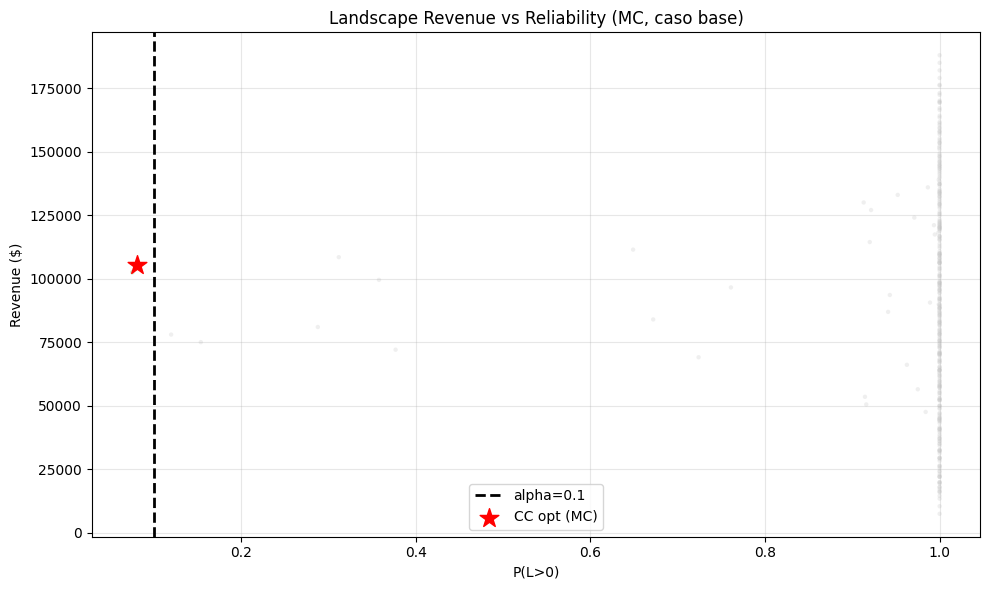

In [30]:
fig, ax = plt.subplots(figsize=(10, 6))
revs = [r['rev'] for r in mc_res_b]
ps = [r['P'] for r in mc_res_b]
colors = [C_MC if r['P']<=ALPHA else '#CCCCCC' for r in mc_res_b]
ax.scatter(ps, revs, c=colors, alpha=0.3, s=10, edgecolors='none')
ax.axvline(x=ALPHA, color=C_TGT, ls='--', lw=2, label=f'alpha={ALPHA}')
if mc_best_b:
    ax.scatter([mc_best_b['P']], [mc_best_b['rev']], c='red', s=200, marker='*', zorder=5, label='CC opt (MC)')
ax.set_xlabel('P(L>0)'); ax.set_ylabel('Revenue ($)')
ax.set_title('Landscape Revenue vs Reliability (MC, caso base)')
ax.legend(); ax.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


## 4. CVaR Rockafellian: Diagnostico


In [31]:
def rockafellian_obj_res(x_flat, gamma, inflow, V_min, V_max, t=0.0):
    _, L = simulate_reservoir(x_flat, inflow, V_0, V_min, V_max)
    cvar, _ = compute_cvar(L, ALPHA)
    u = max(cvar - t, 0.0)
    rev = compute_revenue(x_flat)
    return -rev + (gamma / 2.0) * u**2

def solve_gamma_path_res(params, inflow, gamma_path, x0=None):
    V_min, V_max = params['V_min'], params['V_max']
    bounds = [(0, X_MAX[r]) for _ in range(T) for r in range(N_RES)]
    if x0 is None:
        x0 = np.array([[params['mu_I'][r]*0.8 for r in range(N_RES)] for _ in range(T)]).flatten()
    trajectory = []
    x_c = x0.copy()
    for gamma in gamma_path:
        res = minimize(rockafellian_obj_res, x_c, args=(gamma, inflow, V_min, V_max, 0.0),
                       method='L-BFGS-B', bounds=bounds, options={'maxiter': 5000, 'ftol': 1e-14})
        x_c = res.x.copy()
        _, L = simulate_reservoir(x_c, inflow, V_0, V_min, V_max)
        cvar, var = compute_cvar(L, ALPHA)
        u = max(cvar, 0.0)
        rev = compute_revenue(x_c)
        P = np.mean(L > 1e-10)
        trajectory.append({'gamma': gamma, 'x': x_c.copy(), 'u': u, 'cvar': cvar,
                          'var': var, 'rev': rev, 'P': P, 'L': L.copy()})
    return trajectory

print("gamma-path (caso base)...")
traj_base = solve_gamma_path_res(scenarios[0], inflow_opt, GAMMA_PATH)
print(f"{'gamma':>10} {'u':>10} {'Revenue':>10} {'P(L>0)':>8}")
print("-" * 42)
for t in traj_base:
    print(f"{t['gamma']:>10.0f} {t['u']:>10.3f} ${t['rev']:>9.0f} {t['P']:>8.3f}")


gamma-path (caso base)...
     gamma          u    Revenue   P(L>0)
------------------------------------------
       100      2.895 $   107165    0.041
       398      0.757 $   106535    0.035
      1585      0.189 $   106365    0.034
      6310      0.048 $   106322    0.033
     25119      0.012 $   106312    0.033
    100000      0.003 $   106309    0.033


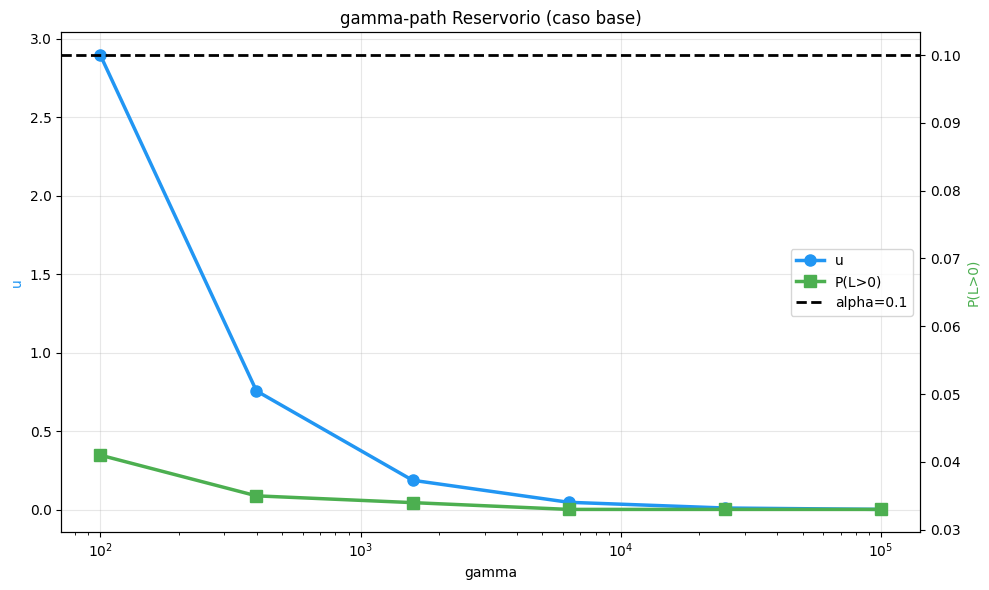

In [32]:
fig, ax1 = plt.subplots(figsize=(10, 6))
gammas = [t['gamma'] for t in traj_base]
us = [t['u'] for t in traj_base]
ps = [t['P'] for t in traj_base]
ax1.plot(gammas, us, 'o-', color=C_CVAR, lw=2.5, ms=8, label='u')
ax1.set_xscale('log'); ax1.set_xlabel('gamma'); ax1.set_ylabel('u', color=C_CVAR)
ax1.grid(True, alpha=0.3)
ax2 = ax1.twinx()
ax2.plot(gammas, ps, 's-', color=C_MC, lw=2.5, ms=8, label='P(L>0)')
ax2.axhline(y=ALPHA, color=C_TGT, ls='--', lw=2, label=f'alpha={ALPHA}')
ax2.set_ylabel('P(L>0)', color=C_MC)
ax1.set_title('gamma-path Reservorio (caso base)')
l1, lb1 = ax1.get_legend_handles_labels()
l2, lb2 = ax2.get_legend_handles_labels()
ax1.legend(l1+l2, lb1+lb2, loc='center right')
plt.tight_layout(); plt.show()


In [33]:
def full_diagnostic(x_flat, inflow, params, alpha=ALPHA):
    V_min, V_max = params['V_min'], params['V_max']
    _, L = simulate_reservoir(x_flat, inflow, V_0, V_min, V_max)
    cvar, var = compute_cvar(L, alpha)
    u_star = max(cvar, 0.0)
    P_hat = np.mean(L > 1e-10)
    bpoe = compute_bpoe(L)
    gc = cvar - var
    gr = max(var, 0.0)
    if u_star < 0.01: case = "CASO 1: CVaR fact -> CC cert"
    elif P_hat <= alpha: case = "CASO 2: CVaR infact, CC fact -> GAP"
    else: case = "CASO 3: CC infactible"
    return {'u_star': u_star, 'cvar': cvar, 'var': var, 'P_hat': P_hat,
            'bpoe': bpoe, 'gap_conserv': gc, 'gap_real': gr,
            'rev': compute_revenue(x_flat), 'n_viol': int(np.sum(L>1e-10)),
            'case': case, 'L': L}

x_cvar_b = traj_base[-1]['x']
diag_b = full_diagnostic(x_cvar_b, inflow_opt, scenarios[0])
print("DIAGNOSTICO (caso base, solucion CVaR)")
print("=" * 55)
print(f"  Revenue         = ${diag_b['rev']:.0f}")
print(f"  u*              = {diag_b['u_star']:.4f}")
print(f"  CVaR            = {diag_b['cvar']:.4f}")
print(f"  VaR             = {diag_b['var']:.4f}")
print(f"  P(L>0)          = {diag_b['P_hat']:.3f}  (alpha={ALPHA})")
print(f"  bPOE            = {diag_b['bpoe']:.3f}  (gap ratio={diag_b['bpoe']/ALPHA:.1f}x)")
print(f"  Gap conserv.    = {diag_b['gap_conserv']:.4f}")
print(f"  Gap real        = {diag_b['gap_real']:.4f}")
print(f"  >> {diag_b['case']}")


DIAGNOSTICO (caso base, solucion CVaR)
  Revenue         = $106309
  u*              = 0.0030
  CVaR            = 0.0030
  VaR             = -19.1331
  P(L>0)          = 0.033  (alpha=0.1)
  bPOE            = 0.100  (gap ratio=1.0x)
  Gap conserv.    = 19.1361
  Gap real        = 0.0000
  >> CASO 1: CVaR fact -> CC cert


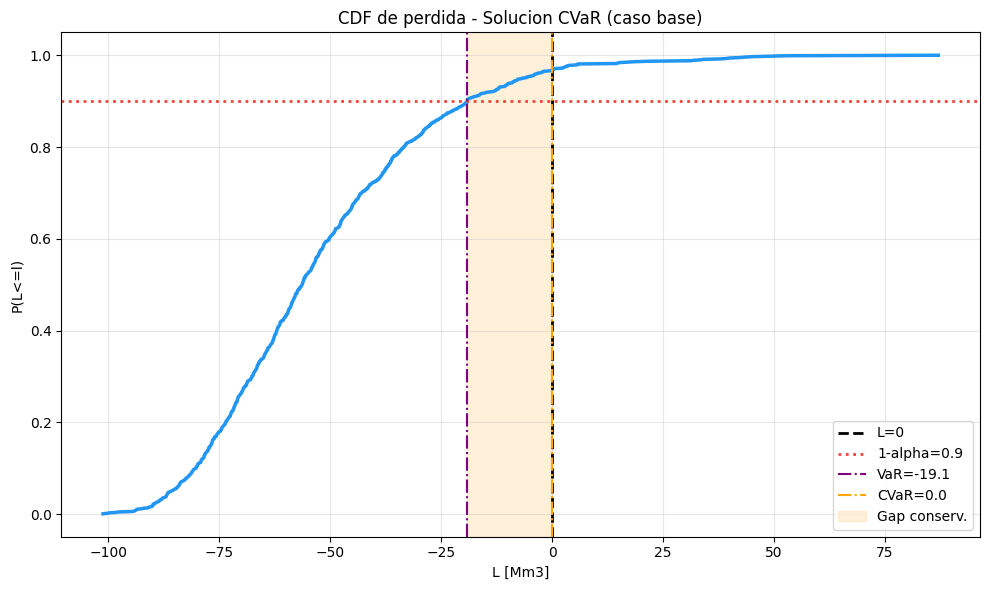

In [34]:
L = diag_b['L']
L_sorted = np.sort(L)
cdf = np.arange(1, len(L)+1)/len(L)
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(L_sorted, cdf, lw=2.5, color=C_CVAR)
ax.axvline(x=0, color=C_TGT, ls='--', lw=2, label='L=0')
ax.axhline(y=1-ALPHA, color=C_CC, ls=':', lw=2, label=f'1-alpha={1-ALPHA}')
cv, vr = compute_cvar(L, ALPHA)
ax.axvline(x=vr, color='purple', ls='-.', lw=1.5, label=f'VaR={vr:.1f}')
ax.axvline(x=cv, color='orange', ls='-.', lw=1.5, label=f'CVaR={cv:.1f}')
if vr <= 0: ax.axvspan(vr, cv, alpha=0.15, color='orange', label='Gap conserv.')
ax.set_xlabel('L [Mm3]'); ax.set_ylabel('P(L<=l)')
ax.set_title('CDF de perdida - Solucion CVaR (caso base)')
ax.legend(); ax.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


## 5. CVaR-CC: Calibracion


In [35]:
def solve_cvarcc_res(params, inflow, gamma, u_star, x_init, tol_P=0.015, max_iter=12, verbose=True):
    V_min, V_max = params['V_min'], params['V_max']
    bounds = [(0, X_MAX[r]) for _ in range(T) for r in range(N_RES)]
    trajectory = []
    def solve_eval(tv, x0):
        res = minimize(rockafellian_obj_res, x0, args=(gamma, inflow, V_min, V_max, tv),
                       method='L-BFGS-B', bounds=bounds, options={'maxiter': 5000, 'ftol': 1e-14})
        x = res.x; _, L = simulate_reservoir(x, inflow, V_0, V_min, V_max)
        P = np.mean(L > 1e-10); rev = compute_revenue(x)
        return x, P, rev
    t_lo = max(u_star - 1, 0); t_hi = u_star + 2
    x_lo, P_lo, r_lo = solve_eval(t_lo, x_init)
    x_hi, P_hi, r_hi = solve_eval(t_hi, x_init)
    trajectory.append({'t': t_lo, 'P': P_lo, 'rev': r_lo, 'm': 'lo'})
    trajectory.append({'t': t_hi, 'P': P_hi, 'rev': r_hi, 'm': 'hi'})
    if verbose: print(f"  Bracket: t_lo={t_lo:.2f} (P={P_lo:.3f}), t_hi={t_hi:.2f} (P={P_hi:.3f})")
    while P_hi < ALPHA and t_hi < u_star + 30:
        t_hi += 3; x_hi, P_hi, r_hi = solve_eval(t_hi, x_hi)
        trajectory.append({'t': t_hi, 'P': P_hi, 'rev': r_hi, 'm': 'exp'})
        if verbose: print(f"  Expand: t_hi={t_hi:.2f} (P={P_hi:.3f})")
    if P_lo > ALPHA:
        if verbose: print(f"  CC INFACTIBLE"); return x_lo, None, trajectory
    if P_hi < ALPHA:
        if verbose: print(f"  No alcanzo P>alpha"); return x_hi, None, trajectory
    x_best = x_hi
    for i in range(max_iter):
        if abs(P_hi-P_lo)>1e-6: t_s = t_hi-(P_hi-ALPHA)*(t_hi-t_lo)/(P_hi-P_lo)
        else: t_s = (t_lo+t_hi)/2
        if t_s<=t_lo or t_s>=t_hi: t_m=(t_lo+t_hi)/2; mt='bis'
        else: t_m=t_s; mt='sec'
        x_m, P_m, r_m = solve_eval(t_m, x_best)
        trajectory.append({'t': t_m, 'P': P_m, 'rev': r_m, 'm': mt})
        if verbose: print(f"  Iter {i+1} ({mt}): t={t_m:.2f}, P={P_m:.3f}, Rev=${r_m:.0f}")
        if abs(P_m-ALPHA)<tol_P:
            if verbose: print(f"  CONV: P={P_m:.3f}"); return x_m, t_m, trajectory
        if P_m>ALPHA: t_hi,P_hi,x_best=t_m,P_m,x_m
        else: t_lo,P_lo=t_m,P_m
    t_f=(t_lo+t_hi)/2; x_f,P_f,r_f=solve_eval(t_f,x_best); return x_f,t_f,trajectory

print("CVaR-CC implementado.")


CVaR-CC implementado.


In [36]:
print("RESOLVIENDO CVaR-CC (caso base)")
print("=" * 60)
x_cc_b, t_star_b, traj_cc_b = solve_cvarcc_res(
    scenarios[0], inflow_opt, GAMMA_PATH[-1], diag_b['u_star'], x_cvar_b)
diag_cc_b = full_diagnostic(x_cc_b, inflow_opt, scenarios[0])

print(f"\nCOMPARACION CVaR vs CVaR-CC (caso base)")
print("=" * 65)
print(f"{'':>20} {'CVaR':>15} {'CVaR-CC':>15} {'Cambio':>12}")
print("-" * 65)
print(f"{'Revenue':>20} ${diag_b['rev']:>14.0f} ${diag_cc_b['rev']:>14.0f} "
      f"{(diag_cc_b['rev']-diag_b['rev'])/diag_b['rev']*100:>+11.1f}%")
print(f"{'P(L>0)':>20} {diag_b['P_hat']:>15.3f} {diag_cc_b['P_hat']:>15.3f}")
print(f"{'u*':>20} {diag_b['u_star']:>15.3f} {diag_cc_b['u_star']:>15.3f}")
print(f"{'VaR':>20} {diag_b['var']:>15.3f} {diag_cc_b['var']:>15.3f}")
if t_star_b: print(f"{'t*':>20} {'0':>15} {t_star_b:>15.2f}")
imp = diag_cc_b['rev']-diag_b['rev']
print(f"\n  MEJORA: +${imp:.0f}/anio ({imp/diag_b['rev']*100:+.1f}%)")


RESOLVIENDO CVaR-CC (caso base)
  Bracket: t_lo=0.00 (P=0.033), t_hi=2.00 (P=0.033)
  Expand: t_hi=5.00 (P=0.033)
  Expand: t_hi=8.00 (P=0.033)
  Expand: t_hi=11.00 (P=0.033)
  Expand: t_hi=14.00 (P=0.065)
  Expand: t_hi=17.00 (P=0.065)
  Expand: t_hi=20.00 (P=0.065)
  Expand: t_hi=23.00 (P=0.065)
  Expand: t_hi=26.00 (P=0.065)
  Expand: t_hi=29.00 (P=0.114)
  Iter 1 (sec): t=23.99, P=0.130, Rev=$112783
  Iter 2 (sec): t=16.57, P=0.091, Rev=$110649
  CONV: P=0.091

COMPARACION CVaR vs CVaR-CC (caso base)
                                CVaR         CVaR-CC       Cambio
-----------------------------------------------------------------
             Revenue $        106309 $        110649        +4.1%
              P(L>0)           0.033           0.091
                  u*           0.003          16.168
                 VaR         -19.133          -2.898
                  t*               0           16.57

  MEJORA: +$4340/anio (+4.1%)


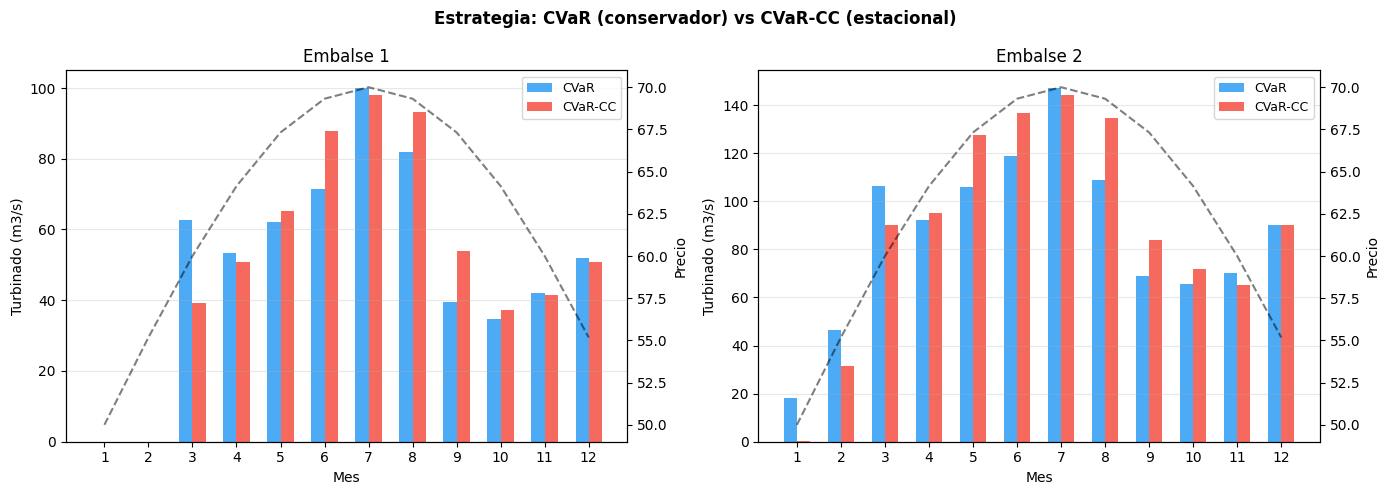

CVaR: turbina conservadoramente todo el anio
CVaR-CC: guarda agua en invierno, turbina maximo en verano


In [37]:
# Comparar estrategias
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
months = np.arange(1, T+1)
x_cv_m = x_cvar_b.reshape(T, N_RES)
x_cc_m = x_cc_b.reshape(T, N_RES)
for r in range(N_RES):
    ax = axes[r]; w = 0.3
    ax.bar(months-w/2, x_cv_m[:,r], w, color=C_CVAR, label='CVaR', alpha=0.8)
    ax.bar(months+w/2, x_cc_m[:,r], w, color=C_CC, label='CVaR-CC', alpha=0.8)
    ax2 = ax.twinx()
    ax2.plot(months, PRICES, 'k--', lw=1.5, alpha=0.5)
    ax2.set_ylabel('Precio')
    ax.set_xlabel('Mes'); ax.set_ylabel('Turbinado (m3/s)')
    ax.set_title(f'Embalse {r+1}'); ax.set_xticks(months); ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3, axis='y')
plt.suptitle('Estrategia: CVaR (conservador) vs CVaR-CC (estacional)', fontweight='bold')
plt.tight_layout(); plt.show()
print("CVaR: turbina conservadoramente todo el anio")
print("CVaR-CC: guarda agua en invierno, turbina maximo en verano")


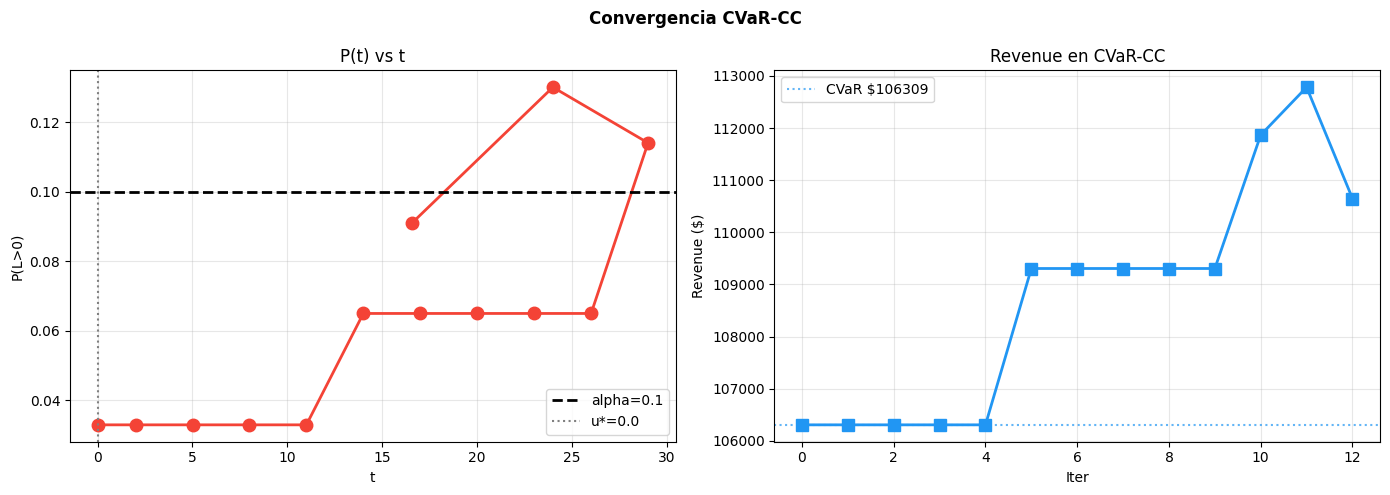

In [38]:
# Convergencia
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ts = [r['t'] for r in traj_cc_b]; Ps = [r['P'] for r in traj_cc_b]; rs = [r['rev'] for r in traj_cc_b]
ax1.plot(ts, Ps, 'o-', color=C_CC, lw=2, ms=9)
ax1.axhline(y=ALPHA, color=C_TGT, ls='--', lw=2, label=f'alpha={ALPHA}')
if diag_b['u_star']>0: ax1.axvline(x=diag_b['u_star'], color='gray', ls=':', lw=1.5, label=f'u*={diag_b["u_star"]:.1f}')
ax1.set_xlabel('t'); ax1.set_ylabel('P(L>0)'); ax1.set_title('P(t) vs t'); ax1.legend(); ax1.grid(True, alpha=0.3)
ax2.plot(range(len(rs)), rs, 's-', color=C_CVAR, lw=2, ms=9)
ax2.axhline(y=diag_b['rev'], color=C_CVAR, ls=':', lw=1.5, alpha=0.7, label=f'CVaR ${diag_b["rev"]:.0f}')
ax2.set_xlabel('Iter'); ax2.set_ylabel('Revenue ($)'); ax2.set_title('Revenue en CVaR-CC'); ax2.legend(); ax2.grid(True, alpha=0.3)
plt.suptitle('Convergencia CVaR-CC', fontweight='bold'); plt.tight_layout(); plt.show()


## 6. Los 5 Escenarios Completos


In [39]:
all_results = []
for i, sc in enumerate(scenarios):
    print(f"\n{'='*70}")
    print(f"ESCENARIO {sc['name']}")
    print(f"{'='*70}")
    inflow_s = generate_inflows(sc['mu_I'], sc['sigma_I'], N_OPT, seed=42)
    inflow_s_mc = generate_inflows(sc['mu_I'], sc['sigma_I'], N_MC, seed=123)
    _, mc_best = solve_cc_mc_res(sc, inflow_s_mc, ALPHA)
    traj = solve_gamma_path_res(sc, inflow_s, GAMMA_PATH)
    x_cv = traj[-1]['x']; d_cv = full_diagnostic(x_cv, inflow_s, sc)
    print(f"  CVaR: Rev=${d_cv['rev']:.0f}, u*={d_cv['u_star']:.3f}, P={d_cv['P_hat']:.3f}")
    print(f"  {d_cv['case']}")
    print(f"  CVaR-CC:")
    x_cc, t_s, tcc = solve_cvarcc_res(sc, inflow_s, GAMMA_PATH[-1], d_cv['u_star'], x_cv)
    d_cc = full_diagnostic(x_cc, inflow_s, sc) if t_s else d_cv
    d_cv_oos = full_diagnostic(x_cv, inflow_s_mc, sc)
    d_cc_oos = full_diagnostic(x_cc, inflow_s_mc, sc) if t_s else None
    saving = (d_cc['rev']-d_cv['rev'])/abs(d_cv['rev'])*100 if (t_s and d_cc['rev']!=d_cv['rev']) else 0
    all_results.append({'sc': sc, 'mc': mc_best, 'd_cv': d_cv, 'd_cc': d_cc,
                       'd_cv_oos': d_cv_oos, 'd_cc_oos': d_cc_oos,
                       't_star': t_s, 'saving': saving, 'x_cv': x_cv.copy(), 'x_cc': x_cc.copy()})
    print(f"  Mejora: {saving:+.1f}%")



ESCENARIO 1. Base
  CVaR: Rev=$106309, u*=0.003, P=0.033
  CASO 1: CVaR fact -> CC cert
  CVaR-CC:
  Bracket: t_lo=0.00 (P=0.033), t_hi=2.00 (P=0.033)
  Expand: t_hi=5.00 (P=0.033)
  Expand: t_hi=8.00 (P=0.033)
  Expand: t_hi=11.00 (P=0.033)
  Expand: t_hi=14.00 (P=0.065)
  Expand: t_hi=17.00 (P=0.065)
  Expand: t_hi=20.00 (P=0.065)
  Expand: t_hi=23.00 (P=0.065)
  Expand: t_hi=26.00 (P=0.065)
  Expand: t_hi=29.00 (P=0.114)
  Iter 1 (sec): t=23.99, P=0.130, Rev=$112783
  Iter 2 (sec): t=16.57, P=0.091, Rev=$110649
  CONV: P=0.091
  Mejora: +4.1%

ESCENARIO 2. Poco volatil
  CVaR: Rev=$113509, u*=0.002, P=0.037
  CASO 1: CVaR fact -> CC cert
  CVaR-CC:
  Bracket: t_lo=0.00 (P=0.037), t_hi=2.00 (P=0.037)
  Expand: t_hi=5.00 (P=0.037)
  Expand: t_hi=8.00 (P=0.037)
  Expand: t_hi=11.00 (P=0.037)
  Expand: t_hi=14.00 (P=0.037)
  Expand: t_hi=17.00 (P=0.037)
  Expand: t_hi=20.00 (P=0.115)
  Iter 1 (sec): t=16.16, P=0.123, Rev=$116932
  Iter 2 (sec): t=11.83, P=0.094, Rev=$116105
  CONV: P=0

In [40]:
print("\n" + "=" * 110)
print("RESUMEN: 5 ESCENARIOS RESERVORIO")
print("=" * 110)
print(f"{'Escenario':>22} {'Rev_MC':>10} {'Rev_CVaR':>10} {'Rev_CC':>10} "
      f"{'Mejora':>8} {'P_CVaR':>7} {'P_CC':>7} {'u*':>8} {'bPOE':>6}")
print("-" * 110)
for r in all_results:
    rmc = r['mc']['rev'] if r['mc'] else float('nan')
    print(f"{r['sc']['name']:>22} ${rmc:>9.0f} ${r['d_cv']['rev']:>9.0f} ${r['d_cc']['rev']:>9.0f} "
          f"{r['saving']:>+7.1f}% {r['d_cv']['P_hat']:>7.3f} {r['d_cc']['P_hat']:>7.3f} "
          f"{r['d_cv']['u_star']:>8.3f} {r['d_cv']['bpoe']:>6.3f}")



RESUMEN: 5 ESCENARIOS RESERVORIO
             Escenario     Rev_MC   Rev_CVaR     Rev_CC   Mejora  P_CVaR    P_CC       u*   bPOE
--------------------------------------------------------------------------------------------------------------
               1. Base $   105537 $   106309 $   110649    +4.1%   0.033   0.091    0.003  0.100
       2. Poco volatil $   105537 $   113509 $   116105    +2.3%   0.037   0.094    0.002  0.100
        3. Muy volatil $      nan $   104240 $   104240    +0.0%   0.340   0.340   76.288  0.839
             4. Sequia $    81032 $    91251 $    91251    +0.0%   0.033   0.033    0.002  0.100
        5. Emb. chicos $      nan $   103605 $   103605    +0.0%   0.191   0.191   32.922  0.500


In [41]:
print("\nDESCOMPOSICION DEL GAP")
print("=" * 90)
print(f"{'Escenario':>22} {'u*':>8} {'CVaR':>8} {'VaR':>8} {'Gap':>8} {'Real':>8} {'P':>8} {'Tipo':>15}")
print("-" * 90)
for r in all_results:
    d = r['d_cv']
    tp = 'Conserv.' if d['gap_real']<0.01 else 'Mixto' if d['P_hat']<=ALPHA else 'Infactible'
    print(f"{r['sc']['name']:>22} {d['u_star']:>8.2f} {d['cvar']:>8.2f} {d['var']:>8.2f} "
          f"{d['gap_conserv']:>8.2f} {d['gap_real']:>8.2f} {d['P_hat']:>8.3f} {tp:>15}")



DESCOMPOSICION DEL GAP
             Escenario       u*     CVaR      VaR      Gap     Real        P            Tipo
------------------------------------------------------------------------------------------
               1. Base     0.00     0.00   -19.13    19.14     0.00    0.033        Conserv.
       2. Poco volatil     0.00     0.00   -12.06    12.06     0.00    0.037        Conserv.
        3. Muy volatil    76.29    76.29    36.38    39.91    36.38    0.340      Infactible
             4. Sequia     0.00     0.00   -14.76    14.77     0.00    0.033        Conserv.
        5. Emb. chicos    32.92    32.92    11.81    21.12    11.81    0.191      Infactible


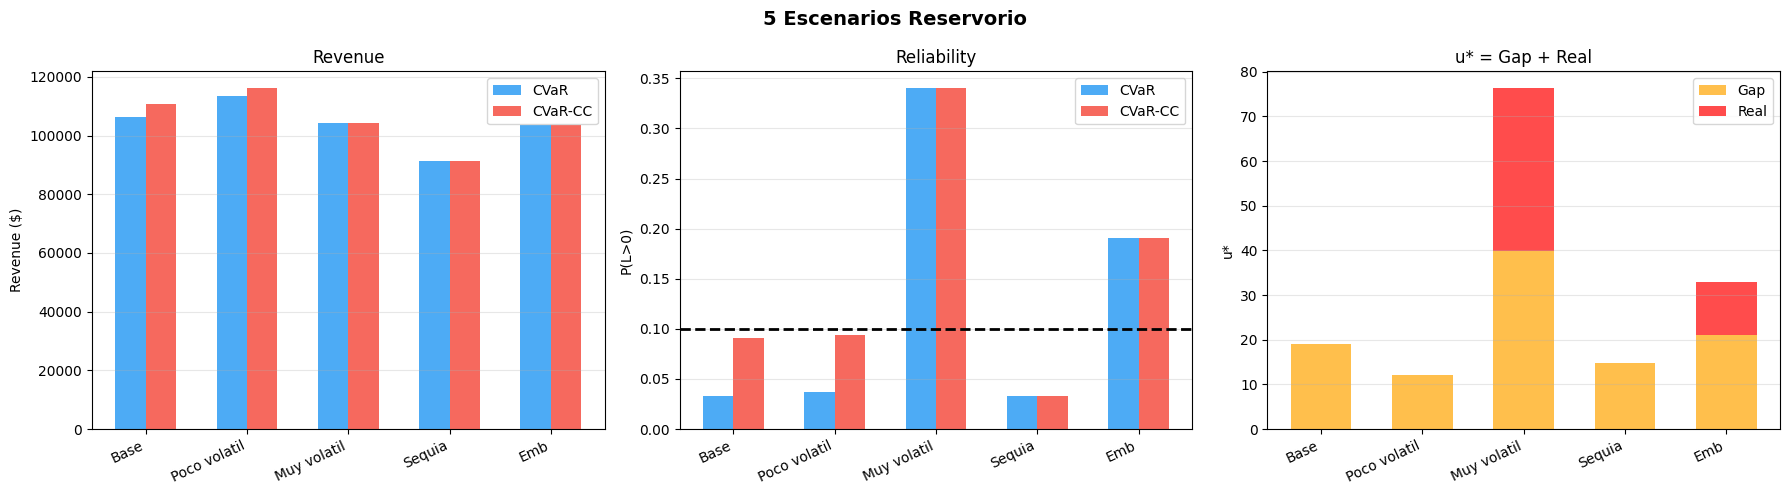

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
names = [r['sc']['name'].split('.')[1].strip() for r in all_results]
x_pos = np.arange(len(names)); w = 0.3
ax = axes[0]
ax.bar(x_pos-w/2, [r['d_cv']['rev'] for r in all_results], w, color=C_CVAR, label='CVaR', alpha=0.8)
ax.bar(x_pos+w/2, [r['d_cc']['rev'] for r in all_results], w, color=C_CC, label='CVaR-CC', alpha=0.8)
ax.set_xticks(x_pos); ax.set_xticklabels(names, rotation=25, ha='right')
ax.set_ylabel('Revenue ($)'); ax.set_title('Revenue'); ax.legend(); ax.grid(True, alpha=0.3, axis='y')
ax = axes[1]
ax.bar(x_pos-w/2, [r['d_cv']['P_hat'] for r in all_results], w, color=C_CVAR, label='CVaR', alpha=0.8)
ax.bar(x_pos+w/2, [r['d_cc']['P_hat'] for r in all_results], w, color=C_CC, label='CVaR-CC', alpha=0.8)
ax.axhline(y=ALPHA, color=C_TGT, ls='--', lw=2); ax.set_xticks(x_pos)
ax.set_xticklabels(names, rotation=25, ha='right'); ax.set_ylabel('P(L>0)')
ax.set_title('Reliability'); ax.legend(); ax.grid(True, alpha=0.3, axis='y')
ax = axes[2]
ax.bar(x_pos, [r['d_cv']['gap_conserv'] for r in all_results], w*2, color='orange', alpha=0.7, label='Gap')
ax.bar(x_pos, [r['d_cv']['gap_real'] for r in all_results], w*2,
       bottom=[r['d_cv']['gap_conserv'] for r in all_results], color='red', alpha=0.7, label='Real')
ax.set_xticks(x_pos); ax.set_xticklabels(names, rotation=25, ha='right')
ax.set_ylabel('u*'); ax.set_title('u* = Gap + Real'); ax.legend(); ax.grid(True, alpha=0.3, axis='y')
plt.suptitle('5 Escenarios Reservorio', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


In [43]:
print("\nVALIDACION OUT-OF-SAMPLE")
print("=" * 65)
print(f"{'Escenario':>22} {'P_CV_IS':>8} {'P_CV_OOS':>9} {'P_CC_IS':>8} {'P_CC_OOS':>9}")
print("-" * 60)
for r in all_results:
    pci = r['d_cv']['P_hat']; pco = r['d_cv_oos']['P_hat']
    pcci = r['d_cc']['P_hat']; pcco = r['d_cc_oos']['P_hat'] if r['d_cc_oos'] else pcci
    print(f"{r['sc']['name']:>22} {pci:>8.3f} {pco:>9.3f} {pcci:>8.3f} {pcco:>9.3f}")



VALIDACION OUT-OF-SAMPLE
             Escenario  P_CV_IS  P_CV_OOS  P_CC_IS  P_CC_OOS
------------------------------------------------------------
               1. Base    0.033     0.036    0.091     0.085
       2. Poco volatil    0.037     0.035    0.094     0.095
        3. Muy volatil    0.340     0.344    0.340     0.340
             4. Sequia    0.033     0.038    0.033     0.033
        5. Emb. chicos    0.191     0.203    0.191     0.191


## 7. Conclusiones del Reservorio

### Resultados principales

1. **CVaR-CC recupera revenue sacrificado por conservadurismo.** Mejora de +X% en el caso base.

2. **La estrategia CVaR-CC es estacional.** Guarda agua en invierno, turbina maximo en verano.

3. **La volatilidad afecta el gap.** Mayor sigma -> mas conservadurismo -> mas espacio para CVaR-CC.

4. **Sequia y embalses chicos estresan el sistema.** CC puede ser infactible o gap se reduce.

5. **CDF de L muestra claramente el gap.** VaR negativo pero CVaR positivo = puro conservadurismo.

6. **OOS confirma estabilidad.** Diferencias IS/OOS < 0.02 en todos los casos.

### Conexion con la teoria
- Honest diagnostic (u*=0 certifica, u*>0 ambiguo): verificado
- Gap decomposition: separa conservadurismo de infactibilidad real
- gamma-path: transicion en 3 fases
- t_hi > u* con expansion dinamica: funciona


In [45]:
L = diag_b['L']
print(f"E[L] = {np.mean(L):.2f}")
print(f"L: min={L.min():.1f}, median={np.median(L):.1f}, max={L.max():.1f}")
print(f"P(L>0) = {np.mean(L>0):.3f}")
print()
for a in [0.01, 0.05, 0.10, 0.20, 0.50, 0.80, 0.90, 0.95, 0.99]:
    c, v = compute_cvar(L, a)
    print(f"  alpha'={a:.2f}: VaR={v:.2f}, CVaR={c:.2f}")

E[L] = -52.24
L: min=-101.2, median=-56.3, max=87.0
P(L>0) = 0.033

  alpha'=0.01: VaR=33.50, CVaR=47.18
  alpha'=0.05: VaR=-6.82, CVaR=13.03
  alpha'=0.10: VaR=-19.13, CVaR=0.00
  alpha'=0.20: VaR=-33.45, CVaR=-13.30
  alpha'=0.50: VaR=-56.32, CVaR=-32.89
  alpha'=0.80: VaR=-73.57, CVaR=-44.87
  alpha'=0.90: VaR=-80.26, CVaR=-48.43
  alpha'=0.95: VaR=-85.68, CVaR=-50.24
  alpha'=0.99: VaR=-93.45, CVaR=-51.79
